In [3]:
# 분류 데이터와 LightGBM 모델, 평가 도구를 불러옵니다.
import lightgbm as lgb
import matplotlib.pyplot as plt
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split

print("LightGBM version:", lgb.__version__)

LightGBM version: 4.5.0


In [4]:
# 유방암 데이터를 특성, 정답 레이블로 나누고 학습, 검증, 테스트 세트를 구성합니다.
dataset = load_breast_cancer()
X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
y = pd.Series(dataset.target, name="target")

X_fit, X_test, y_fit, y_test = train_test_split(
    X, y, test_size=0.2, random_state=156, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_fit, y_fit, test_size=0.1, random_state=156, stratify=y_fit
)
print("Training:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)

Training: (409, 30) Validation: (46, 30) Test: (114, 30)


In [5]:
# 검증 세트의 점수를 보며 LightGBM 모델을 학습합니다.
lgbm_model = LGBMClassifier(
    n_estimators=400,
    learning_rate=0.05,
    random_state=156,
    verbosity=-1,
)
lgbm_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="binary_logloss",
    callbacks=[
        lgb.early_stopping(stopping_rounds=50),
        lgb.log_evaluation(period=50),
    ],
)
print("Best iteration:", lgbm_model.best_iteration_)

Training until validation scores don't improve for 50 rounds
[50]	valid_0's binary_logloss: 0.107547
[100]	valid_0's binary_logloss: 0.0486812
[150]	valid_0's binary_logloss: 0.0247395
[200]	valid_0's binary_logloss: 0.0159566
[250]	valid_0's binary_logloss: 0.0135323
[300]	valid_0's binary_logloss: 0.010835
[350]	valid_0's binary_logloss: 0.00942925
Early stopping, best iteration is:
[318]	valid_0's binary_logloss: 0.00856521
Best iteration: 318


In [6]:
# 보류한 테스트 세트에서 분류 성능을 평가합니다.
preds = lgbm_model.predict(X_test)
pred_probs = lgbm_model.predict_proba(X_test)[:, 1]

print("Confusion matrix:\n", confusion_matrix(y_test, preds))
print(f"Accuracy: {accuracy_score(y_test, preds):.4f}")
print(f"Precision: {precision_score(y_test, preds):.4f}")
print(f"Recall: {recall_score(y_test, preds):.4f}")
print(f"F1 score: {f1_score(y_test, preds):.4f}")
print(f"ROC AUC: {roc_auc_score(y_test, pred_probs):.4f}")

Confusion matrix:
 [[40  2]
 [ 0 72]]
Accuracy: 0.9825
Precision: 0.9730
Recall: 1.0000
F1 score: 0.9863
ROC AUC: 0.9924


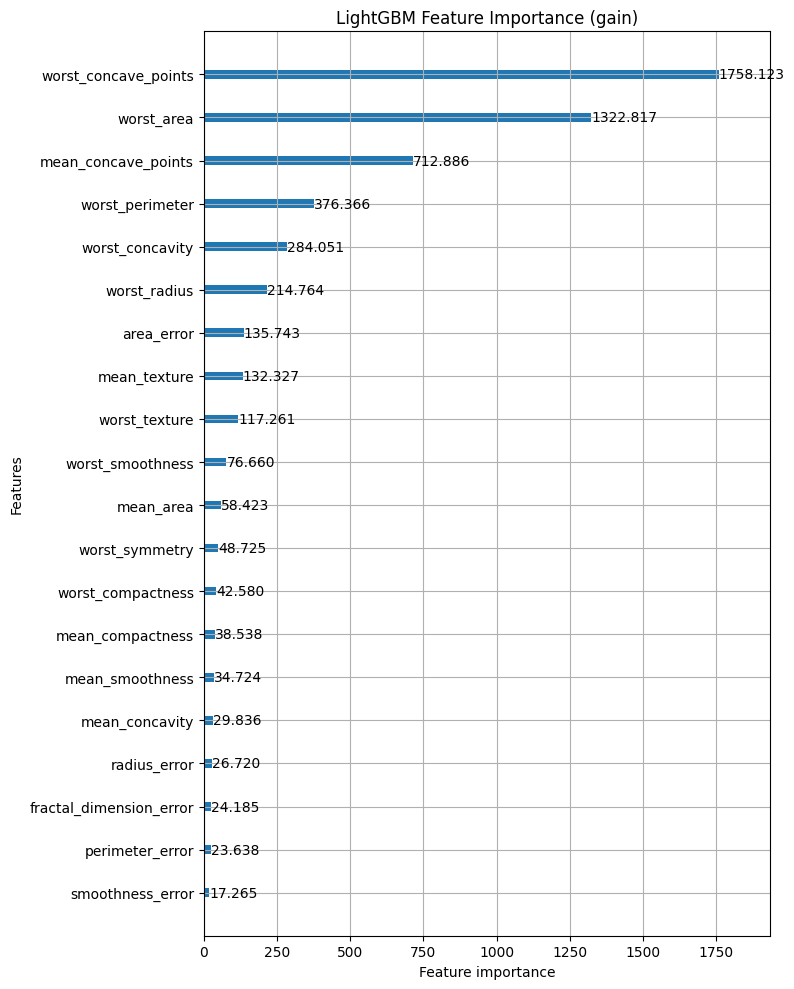

In [7]:
# Gain 기준으로 중요한 특성 20개를 시각화합니다.
fig, ax = plt.subplots(figsize=(8, 10))
lgb.plot_importance(
    lgbm_model,
    ax=ax,
    max_num_features=20,
    importance_type="gain",
)
ax.set_title("LightGBM Feature Importance (gain)")
fig.tight_layout()
plt.show()